# Entrada do oráculo × linguagem/domínio — `oracle_input.png`

Mesmo gráfico de `graphic/oracle/grafico_entrada_linguagem_oracle.ipynb`. Os números vêm das colunas *Oracle context* e *Oracle language* de `../data/tabela_de_codigos_artefatos.csv`: três tipos de entrada, empilhados por linguagem/domínio. Linguagens sem nenhum estudo não aparecem na legenda.

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import dados_artefatos as da
from paleta_grupos import tons_grupo, CINZA_OUTROS, CINZA_INDEFINIDO

# família laranja do grupo oracle
_t = tons_grupo("oracle", 5)
# linguagem/domínio -> (cor, hachura), na ordem de empilhamento
# as quatro com mais estudos recebem tons distintos; as três pequenas dividem o tom mais claro
# e se distinguem pela hachura; "Other" fica em cinza
cores_ling = {
    "Java":     (_t[4], None),
    "Python":   (_t[3], None),
    "GUI/web":  (_t[2], None),
    "C/C++":    (_t[1], None),
    "JS/TS":    (_t[0], ".."),
    "Rust":     (_t[0], "xx"),
    "Solidity": (_t[0], "//"),
    "Other":    (CINZA_OUTROS, None),
}
_codigo = {"Java": "OL1", "Python": "OL2", "GUI/web": "OL3", "C/C++": "OL4", "JS/TS": "OL5", "Rust": "OL6",
           "Solidity": "OL7", "Other": "OL8"}

In [2]:
# Estudos por tipo de entrada do oráculo, separados por linguagem/domínio
rotulos = {"OX1": "Source code /\ncode context", "OX2": "Specification / description\nin natural language",
           "OX3": "Other (state models,\nexecution feedback, traces...)"}
tabela = da.cruzamento("Oracle context", "Oracle language")
ordem = sorted([c for c in rotulos if c != "OX3"], key=lambda c: -tabela.loc[c].sum()) + ["OX3"]   # decrescente, "Other" no fim
dados = [{"tipo": rotulos[c], "segmentos": {l: int(tabela.loc[c, cod]) for l, cod in _codigo.items()}} for c in ordem]

x_pos = range(len(dados))
totais_ling = {l: sum(d["segmentos"].get(l, 0) for d in dados) for l in cores_ling}
total = sum(totais_ling.values())
print(totais_ling, "total =", total, [sum(d["segmentos"].values()) for d in dados])
assert total == len(da.estudos("Oracle context"))

{'Java': 25, 'Python': 18, 'GUI/web': 11, 'C/C++': 2, 'JS/TS': 0, 'Rust': 1, 'Solidity': 1, 'Other': 32} total = 90 [41, 35, 14]


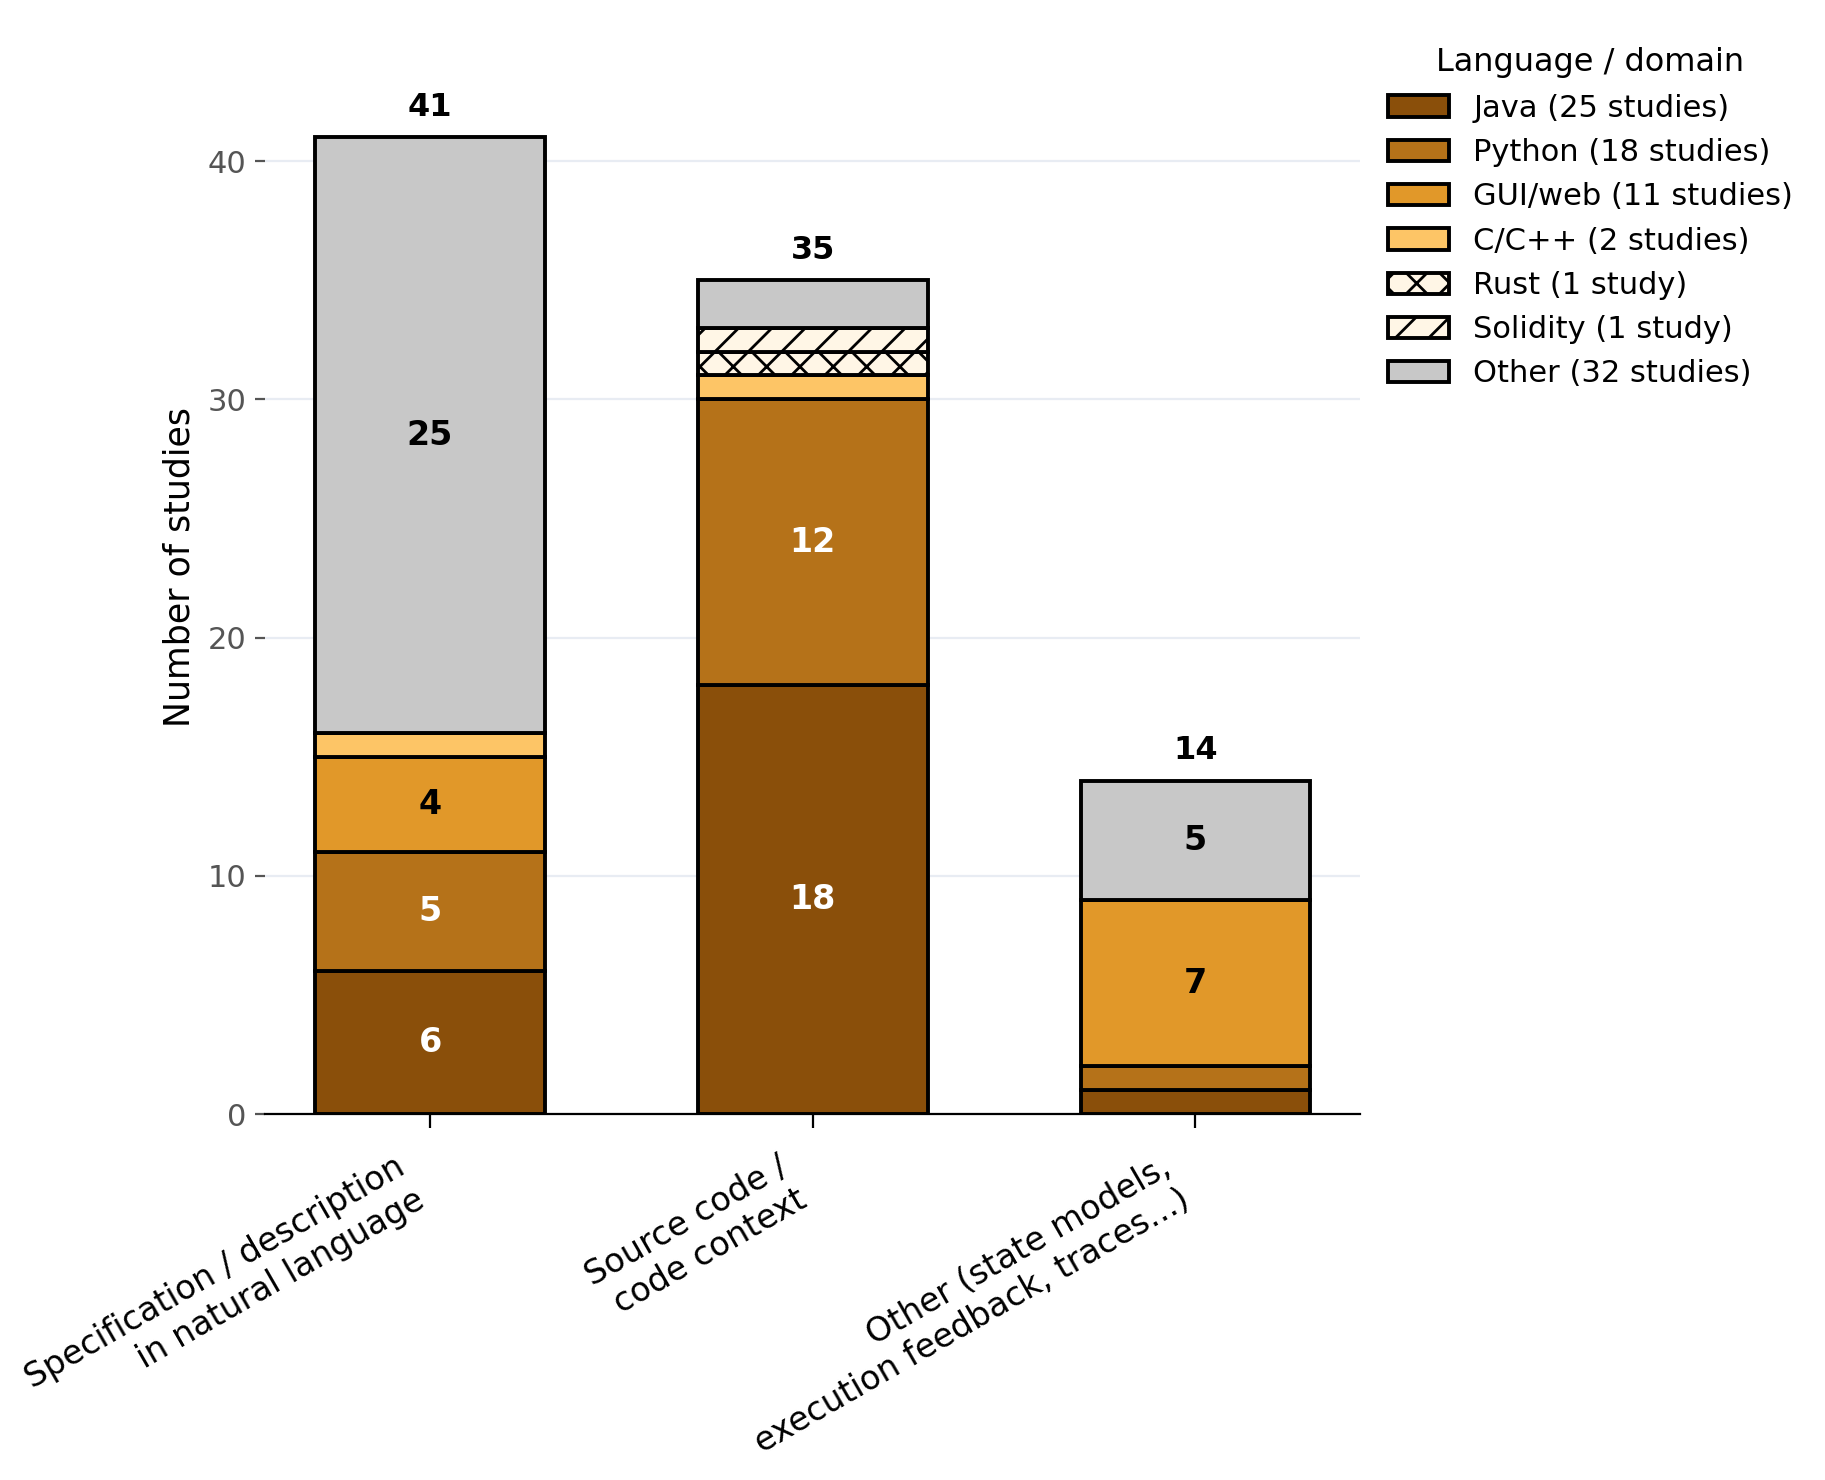

In [3]:
def cor_texto_legivel(hex_cor):
    r, g, b = (int(hex_cor[i : i + 2], 16) for i in (1, 3, 5))
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    return "black" if luminancia > 150 else "white"

fig, ax = plt.subplots(figsize=(9, 7.5), dpi=200)

for x, d in zip(x_pos, dados):
    base = 0
    for ling, (cor, hachura) in cores_ling.items():   # empilha sempre na ordem da legenda
        v = d["segmentos"].get(ling, 0)
        if v == 0:
            continue
        ax.bar(x, v, bottom=base, color=cor, hatch=hachura, width=0.6, edgecolor="black", linewidth=1.4, zorder=3)
        # número dentro do segmento só quando cabe
        if v >= 3:
            ax.text(x, base + v / 2, str(v), ha="center", va="center", fontsize=12,
                    fontweight="bold", color=cor_texto_legivel(cor), zorder=4)
        base += v
    ax.text(x, base + 0.6, str(base), ha="center", va="bottom", fontsize=11.5,
            fontweight="bold", color="black")

ax.set_xticks(list(x_pos))
ax.set_xticklabels([d["tipo"] for d in dados], rotation=30, ha="right", fontsize=12)

ax.set_ylim(0, max(sum(d["segmentos"].values()) for d in dados) * 1.12)
ax.set_ylabel("Number of studies", fontsize=12.5)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="x", length=5, pad=8, color="black")
ax.tick_params(axis="y", colors="#555555", labelsize=11)
ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor=cor, hatch=hachura, edgecolor="black", linewidth=1.4,
          label=f"{ling} ({totais_ling[ling]} stud{'ies' if totais_ling[ling] != 1 else 'y'})")
    for ling, (cor, hachura) in cores_ling.items() if totais_ling[ling] > 0
]
ax.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=11,
          title="Language / domain", title_fontsize=11.5)

plt.tight_layout()
plt.savefig("oracle_input.png", bbox_inches="tight", dpi=200)
plt.savefig("oracle_input.pdf", bbox_inches="tight")
plt.show()